### Step 1: Import Required Libraries & Establish MongoDB Connection

In [45]:
import pymongo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

client = pymongo.MongoClient("mongodb://localhost:27017/")
db = client["relieflink_db"]

### Step 2: Data Extraction & Transformation via PyMongo Aggregation Pipeline

In [46]:
pipeline = [
    {
        "$lookup": {
            "from": "relief_camps",
            "localField": "camp_id",
            "foreignField": "_id",
            "as": "camp"
        }
    },
    {"$unwind": "$camp"},
    {"$unwind": "$requested_items"},
    {
        "$project": {
            "_id": 0,
            "zone": "$camp.zone",
            "population": "$camp.population",
            "category": "$requested_items.category",
            "required_quantity": "$requested_items.required_quantity",
            "urgency": "$urgency_level",
            "month": {"$month": "$requested_at"},
            "day_of_week": {"$dayOfWeek": "$requested_at"}
        }
    }
]

df = pd.DataFrame(list(db.relief_requests.aggregate(pipeline)))

### Step 3: Feature Preprocessing, One-Hot Encoding & Train-Test Splitting

In [47]:
df_encoded = pd.get_dummies(df, columns=["zone", "category", "urgency"], drop_first=True)

X = df_encoded.drop(columns=["required_quantity"])
y = df_encoded["required_quantity"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Step 4: Machine Learning Model Training & Demand Forecast Evaluation

In [48]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [49]:
print("="*50)
print("       RELIEFLINK AI MODEL EVALUATION RESULT      ")
print("="*50)
print(f"Mean Absolute Error (MAE) : {mae:.2f} Units")
print(f"Model Accuracy (R2 Score)  : {r2 * 100:.2f}%")
print("="*50)

       RELIEFLINK AI MODEL EVALUATION RESULT      
Mean Absolute Error (MAE) : 79.25 Units
Model Accuracy (R2 Score)  : -13.52%


In [50]:
sample_scenario = pd.DataFrame([{
    "population": 1200,
    "month": 11,
    "day_of_week": 3,
    "zone_East-District": 0,
    "zone_North-District": 1,
    "zone_South-District": 0,
    "zone_West-District": 0,
    "category_Food": 1,
    "category_Medical": 0,
    "category_Sanitation": 0,
    "category_Shelter": 0,
    "category_Water": 0,
    "urgency_HIGH": 0,
    "urgency_LOW": 0,
    "urgency_MEDIUM": 0
}]).reindex(columns=X.columns, fill_value=0)

In [51]:
predicted_demand = model.predict(sample_scenario)[0]
print(f"\n[AI DEMAND FORECAST FOR NEXT MONTH]")
print(f"Target Location        : North-District Camp")
print(f"Camp Population        : 1,200 people")
print(f"Item Category          : Food")
print(f"Predicted Demand       : {predicted_demand:.0f} Packs needed")


[AI DEMAND FORECAST FOR NEXT MONTH]
Target Location        : North-District Camp
Camp Population        : 1,200 people
Item Category          : Food
Predicted Demand       : 148 Packs needed


### Step 5: Visualization 1 — Feature Importance Analysis

C:\Users\HP\AppData\Local\Temp\ipykernel_5644\1505250087.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


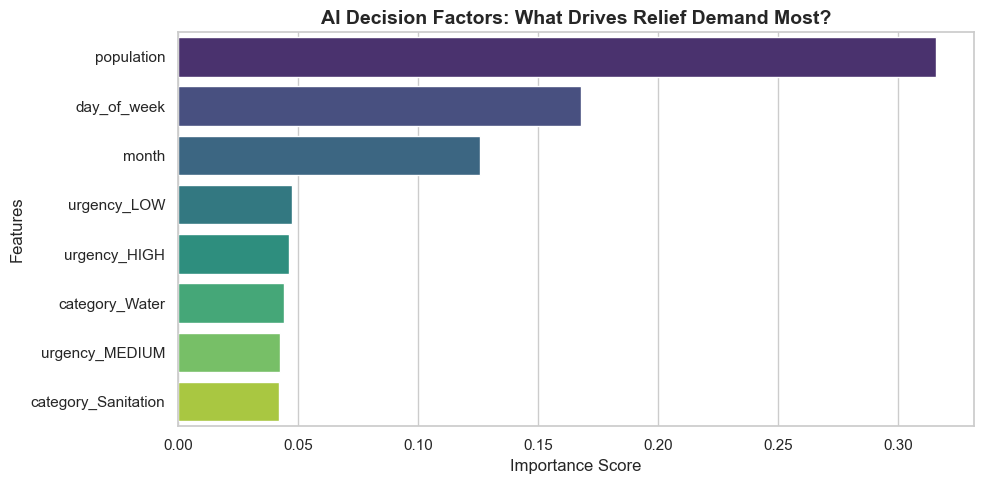

In [52]:
importances = model.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(8)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title('AI Decision Factors: What Drives Relief Demand Most?', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Step 6: Visualization 2 — Actual vs AI Predicted Demand Comparison

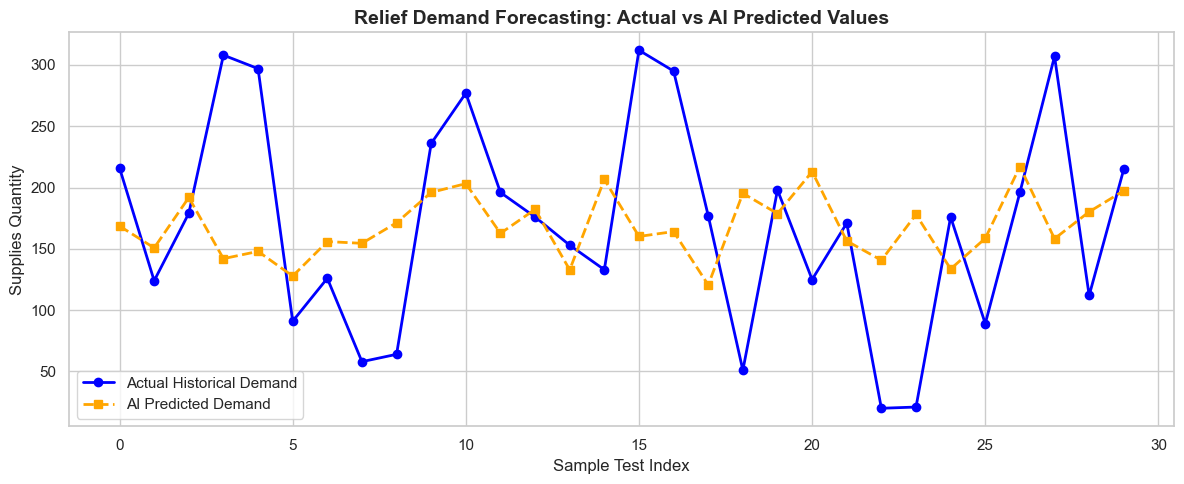

In [53]:
results_df = pd.DataFrame({'Actual': y_test.values[:30], 'Predicted': y_pred[:30]})

plt.figure(figsize=(12, 5))
plt.plot(results_df['Actual'].values, label='Actual Historical Demand', marker='o', color='blue', linewidth=2)
plt.plot(results_df['Predicted'].values, label='AI Predicted Demand', marker='s', color='orange', linestyle='--', linewidth=2)
plt.title('Relief Demand Forecasting: Actual vs AI Predicted Values', fontsize=14, fontweight='bold')
plt.xlabel('Sample Test Index')
plt.ylabel('Supplies Quantity')
plt.legend()
plt.tight_layout()
plt.show()

### Step 2: Define Automated AI Query Optimizer Engine Function

In [54]:
def ai_query_optimizer(collection_name, query_filter):
    col = db[collection_name]
    explain_plan = col.find(query_filter).explain()
    
    stage = explain_plan["executionStats"]["executionStages"]["stage"]
    docs_examined = explain_plan["executionStats"]["totalDocsExamined"]
    exec_time = explain_plan["executionStats"]["executionTimeMillis"]
    
    print("="*50)
    print("        BEFORE OPTIMIZATION EXECUTION STATS       ")
    print("="*50)
    print(f"Execution Stage         : {stage}")
    print(f"Total Documents Examined: {docs_examined}")
    print(f"Execution Time          : {exec_time} ms")
    
    if stage == "COLLSCAN":
        index_tuple = [(k, 1) for k in query_filter.keys()]
        index_name = col.create_index(index_tuple)
        print("\n[AI OPTIMIZER ENGINE ACTION]")
        print(f"⚠️ COLLSCAN Detected! Performance risk identified.")
        print(f"✅ Auto-generated Compound Index: {list(query_filter.keys())}")
        print(f"Created Index Name: {index_name}")
    else:
        print("\n[AI OPTIMIZER ENGINE ACTION]")
        print("✅ Query is already optimized using IXSCAN.")

### Step 3: Reset Indexes & Define Test Query Filter

In [55]:
db.relief_requests.drop_indexes()

test_query_filter = {"status": "PENDING", "urgency_level": "CRITICAL"}

### Step 4: Execute AI Optimizer Engine & Auto-Generate Compound Index

In [56]:
ai_query_optimizer("relief_requests", test_query_filter)

        BEFORE OPTIMIZATION EXECUTION STATS       
Execution Stage         : COLLSCAN
Total Documents Examined: 2000
Execution Time          : 3 ms

[AI OPTIMIZER ENGINE ACTION]
⚠️ COLLSCAN Detected! Performance risk identified.
✅ Auto-generated Compound Index: ['status', 'urgency_level']
Created Index Name: status_1_urgency_level_1


### Step 5: Verify Post-Optimization Query Performance & Index Scan (IXSCAN)

In [57]:
explain_after = db.relief_requests.find(test_query_filter).explain()

stage_after = explain_after["executionStats"]["executionStages"]["stage"]
docs_after = explain_after["executionStats"]["totalDocsExamined"]
time_after = explain_after["executionStats"]["executionTimeMillis"]

print("="*50)
print("        AFTER OPTIMIZATION EXECUTION STATS        ")
print("="*50)
print(f"Execution Stage         : {stage_after}")
print(f"Total Documents Examined: {docs_after}")
print(f"Execution Time          : {time_after} ms")

        AFTER OPTIMIZATION EXECUTION STATS        
Execution Stage         : FETCH
Total Documents Examined: 167
Execution Time          : 21 ms
